# HW3 Fashion-MNIST DNN

使用 Fashion-MNIST 資料集建立全連接神經網路進行服飾分類。

## 1. 匯入套件

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import utils
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

np.random.seed(42)
tf.random.set_seed(42)

## 2. 讀取資料

In [2]:
(x_train_image, y_train_label), (x_test_image, y_test_label) = fashion_mnist.load_data()

print("訓練圖片 shape:", x_train_image.shape)
print("訓練標籤 shape:", y_train_label.shape)
print("測試圖片 shape:", x_test_image.shape)
print("測試標籤 shape:", y_test_label.shape)

訓練圖片 shape: (60000, 28, 28)
訓練標籤 shape: (60000,)
測試圖片 shape: (10000, 28, 28)
測試標籤 shape: (10000,)


## 3. 顯示訓練圖片

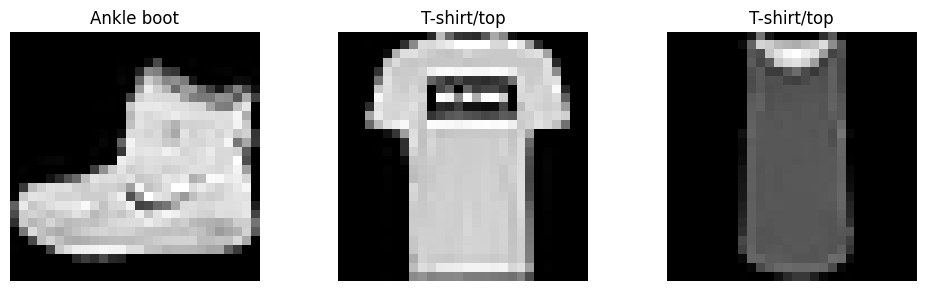

In [3]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

plt.figure(figsize=(10, 3))

for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(x_train_image[i], cmap="gray")
    plt.title(class_names[y_train_label[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

## 4. 資料預處理

In [4]:
x_Train = x_train_image.reshape(60000, 784).astype("float32")
x_Test = x_test_image.reshape(10000, 784).astype("float32")

x_Train_normalize = x_Train / 255.0
x_Test_normalize = x_Test / 255.0

y_Train_OneHot = utils.to_categorical(y_train_label, 10)
y_Test_OneHot = utils.to_categorical(y_test_label, 10)

print("x_Train_normalize shape:", x_Train_normalize.shape)
print("x_Test_normalize shape:", x_Test_normalize.shape)
print("y_Train_OneHot shape:", y_Train_OneHot.shape)
print("y_Test_OneHot shape:", y_Test_OneHot.shape)

x_Train_normalize shape: (60000, 784)
x_Test_normalize shape: (10000, 784)
y_Train_OneHot shape: (60000, 10)
y_Test_OneHot shape: (10000, 10)


## 5. 建立 DNN 模型

網路結構：784 → 512 → 256 → 128 → 10

In [5]:
model = Sequential([
    tf.keras.Input(shape=(784,)),

    Dense(512, activation="relu", kernel_regularizer=l2(0.0001)),
    BatchNormalization(),
    Dropout(0.10),

    Dense(256, activation="relu", kernel_regularizer=l2(0.0001)),
    BatchNormalization(),
    Dropout(0.10),

    Dense(128, activation="relu", kernel_regularizer=l2(0.0001)),
    BatchNormalization(),

    Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 571,018 (2.18 MB)

 Trainable params: 569,226 (2.17 MB)

 Non-trainable params: 1,792 (7.00 KB)

### 各層輸出 shape 與參數量

In [6]:
print("Input shape:", model.input_shape)

for layer in model.layers:
    print(
        layer.name,
        "output shape =", layer.output.shape,
        "params =", layer.count_params()
    )

print("Output shape:", model.output_shape)
print("總參數量:", model.count_params())

Input shape: (None, 784)
dense output shape = (None, 512) params = 401920
batch_normalization output shape = (None, 512) params = 2048
dropout output shape = (None, 512) params = 0
dense_1 output shape = (None, 256) params = 131328
batch_normalization_1 output shape = (None, 256) params = 1024
dropout_1 output shape = (None, 256) params = 0
dense_2 output shape = (None, 128) params = 32896
batch_normalization_2 output shape = (None, 128) params = 512
dense_3 output shape = (None, 10) params = 1290
Output shape: (None, 10)
總參數量: 571018


## 6. 編譯模型

In [7]:
optimizer = tf.keras.optimizers.Adam(learning_rate=0.0005)

model.compile(
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.05),
    optimizer=optimizer,
    metrics=["accuracy"]
)

## 7. 設定 Callback

In [8]:
early_stop = EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=10,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=1e-6
)

## 8. 訓練模型

In [9]:
train_history = model.fit(
    x_Train_normalize,
    y_Train_OneHot,
    validation_split=0.1,
    epochs=100,
    batch_size=128,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8290 - loss: 0.8355 - val_accuracy: 0.8608 - val_loss: 0.7430 - learning_rate: 5.0000e-04
Epoch 2/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8707 - loss: 0.7155 - val_accuracy: 0.8727 - val_loss: 0.7141 - learning_rate: 5.0000e-04
Epoch 3/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8827 - loss: 0.6815 - val_accuracy: 0.8678 - val_loss: 0.7270 - learning_rate: 5.0000e-04
Epoch 4/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8876 - loss: 0.6630 - val_accuracy: 0.8660 - val_loss: 0.7209 - learning_rate: 5.0000e-04
Epoch 5/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8951 - loss: 0.6428 - val_accuracy: 0.8713 - val_loss: 0.7008 - learning_rate: 5.0000e-04
Epoch 6/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8989 - loss: 0.6313 - val_accuracy: 0.8717 - val_loss: 0.6849 - learning_rate: 5.0000e-04
Epoch 7/100
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - acc

## 9. Accuracy

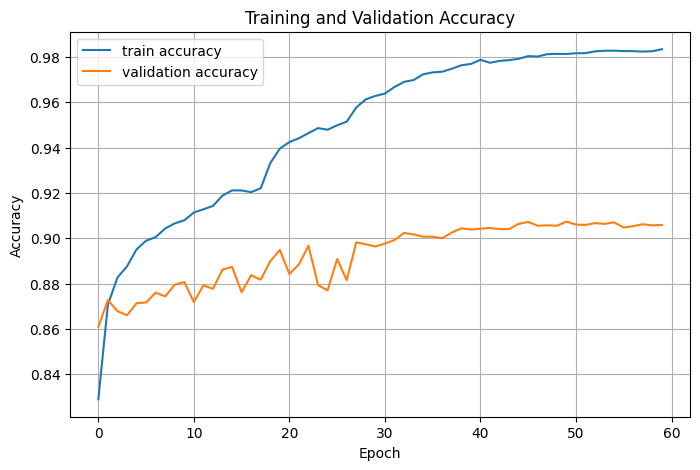

In [10]:
plt.figure(figsize=(8, 5))
plt.plot(train_history.history["accuracy"], label="train accuracy")
plt.plot(train_history.history["val_accuracy"], label="validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

## 10. Loss

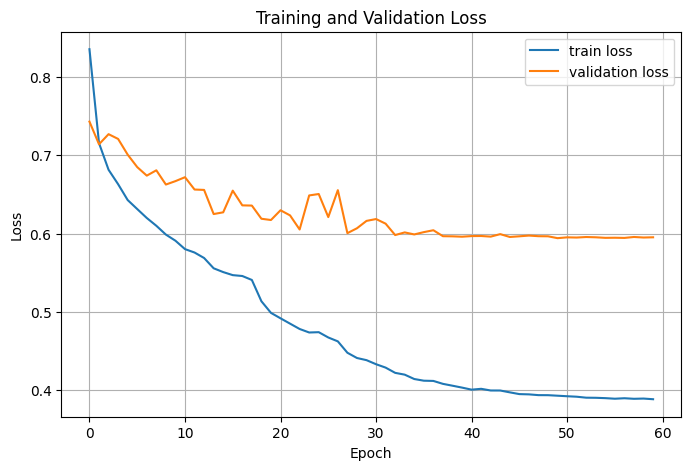

In [11]:
plt.figure(figsize=(8, 5))
plt.plot(train_history.history["loss"], label="train loss")
plt.plot(train_history.history["val_loss"], label="validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()

## 11. 測試資料評估

In [12]:
test_loss, test_accuracy = model.evaluate(
    x_Test_normalize,
    y_Test_OneHot,
    verbose=0
)

print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)
print("Test accuracy (%):", test_accuracy * 100)

Test loss: 0.6128126382827759
Test accuracy: 0.9016000032424927
Test accuracy (%): 90.16000032424927


## 12. 測試資料預測

In [13]:
prediction = model.predict(x_Test_normalize)

predicted_labels = np.argmax(prediction, axis=1)

print("prediction shape:", prediction.shape)
print("前 10 筆預測:", predicted_labels[:10])
print("前 10 筆正確答案:", y_test_label[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
prediction shape: (10000, 10)
前 10 筆預測: [9 2 1 1 6 1 4 6 5 7]
前 10 筆正確答案: [9 2 1 1 6 1 4 6 5 7]


## 13. 顯示預測結果

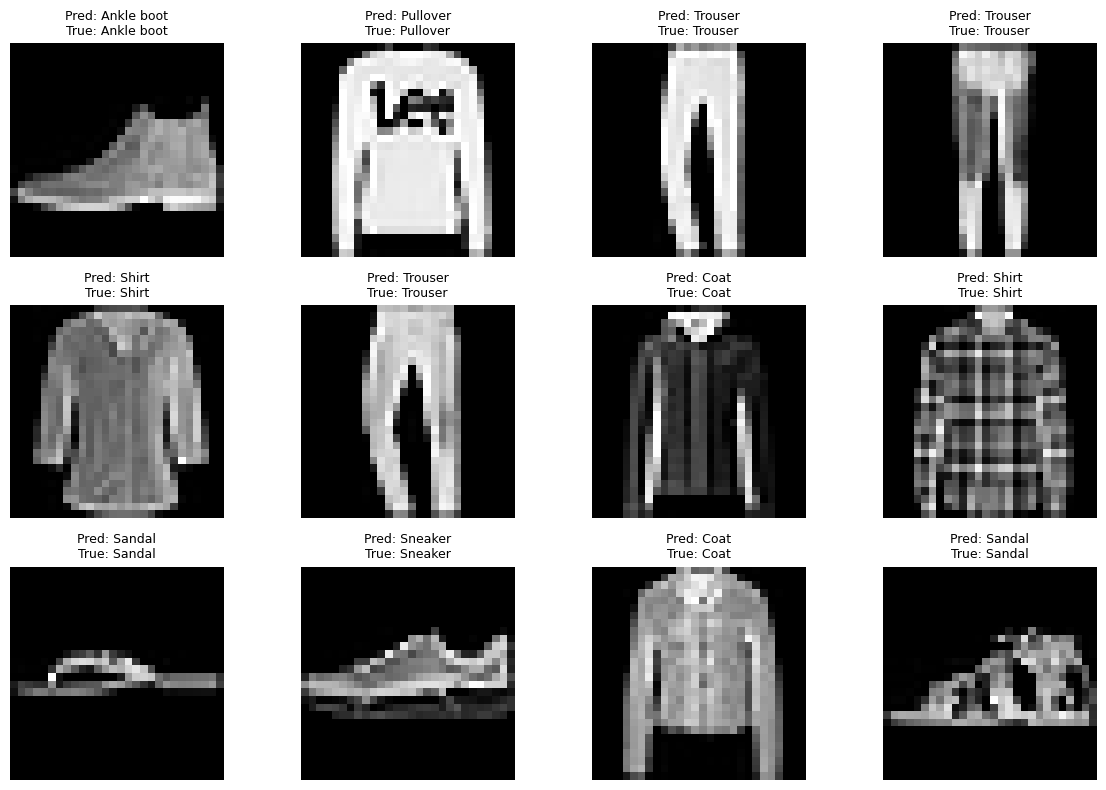

In [14]:
plt.figure(figsize=(12, 8))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(x_test_image[i], cmap="gray")

    pred_name = class_names[predicted_labels[i]]
    true_name = class_names[y_test_label[i]]

    plt.title(
        "Pred: " + pred_name + "\nTrue: " + true_name,
        fontsize=9
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

## 14. Confusion Matrix

In [15]:
cm = tf.math.confusion_matrix(
    y_test_label,
    predicted_labels,
    num_classes=10
).numpy()

print(cm)

[[842   1  13  22   4   1 106   0  11   0]
 [  3 979   1   9   5   0   2   0   1   0]
 [ 13   1 849  12  67   0  57   0   1   0]
 [ 21   7  10 910  29   0  19   0   4   0]
 [  1   0  76  24 848   0  48   0   3   0]
 [  0   0   0   0   0 965   0  23   1  11]
 [113   3  69  29  66   0 711   0   9   0]
 [  0   0   0   0   0  12   0 965   0  23]
 [  5   0   3   6   1   1   4   4 976   0]
 [  1   0   0   0   0   7   0  21   0 971]]


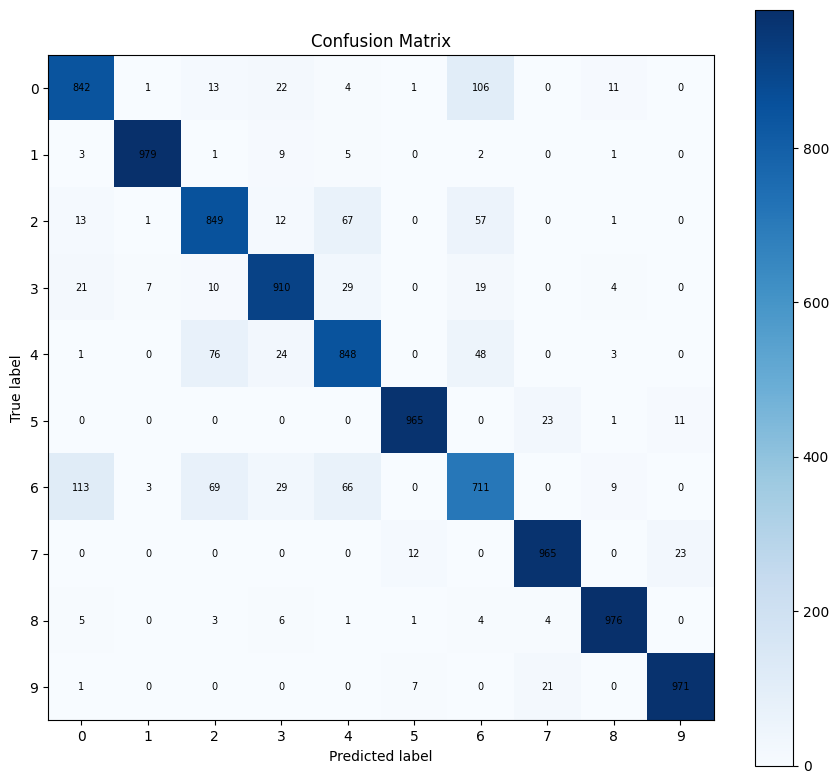

類別編號:
0 = T-shirt/top
1 = Trouser
2 = Pullover
3 = Dress
4 = Coat
5 = Sandal
6 = Shirt
7 = Sneaker
8 = Bag
9 = Ankle boot


In [16]:
plt.figure(figsize=(9, 8))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.colorbar()

plt.xticks(range(10), range(10))
plt.yticks(range(10), range(10))

for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=7)

plt.tight_layout()
plt.show()

print("類別編號:")
for i, name in enumerate(class_names):
    print(i, "=", name)

## 15. 儲存模型


In [18]:
model.save("fashion_mnist_dnn.keras")
print("模型已儲存")

模型已儲存


## 16. 結果

使用 DNN 完成 Fashion-MNIST 分類，
並以 accuracy、loss、預測結果與 Confusion Matrix 觀察模型表現。